# *Setup*

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
%%time
import numpy as np
import pandas as pd

from hid_avan.eda import head_tail_info
from hid_avan.evaluation import evaluate_with_data_splitting
import hid_avan.hydrolab as hl

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(context='notebook', style='ticks')
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['mathtext.fontset'] = 'cm'

CPU times: total: 15.6 ms
Wall time: 16.1 ms


## Carregamento dos Dados

In [3]:
df = pd.read_csv('../../data/processed/pr-et-q_monthly_inner-joined_2.csv', parse_dates=['date'])
df.rename({
    'date':'DATE',
    'avg_q':'Q',
    'agg_total__avg_pr':'P',
    'et':'ETP'
}, axis='columns', inplace=True)
df = df.loc[:, ['DATE', 'P', 'ETP', 'Q']]
head_tail_info(df)

<class 'pandas.DataFrame'>
RangeIndex: 587 entries, 0 to 586
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   DATE    587 non-null    datetime64[us]
 1   P       587 non-null    float64       
 2   ETP     587 non-null    float64       
 3   Q       585 non-null    float64       
dtypes: datetime64[us](1), float64(3)
memory usage: 18.5 KB


,DATE,P,ETP,Q
0,1973-01-01,44.500000,229.4,10.3429
1,1973-02-01,125.700000,176.0,3.0353
2,1973-03-01,271.100000,171.7,35.2784
3,1973-04-01,266.000000,140.9,141.4698
4,1973-05-01,146.600000,147.6,43.2115
582,2021-08-01,0.009741,191.7,0.0200
583,2021-09-01,0.940613,213.9,0.0000
584,2021-10-01,23.644526,245.3,0.0000
585,2021-11-01,31.468279,242.0,4.4730
586,2021-12-01,42.830865,250.0,1.3916


None

# Modelagem via SMAP mensal

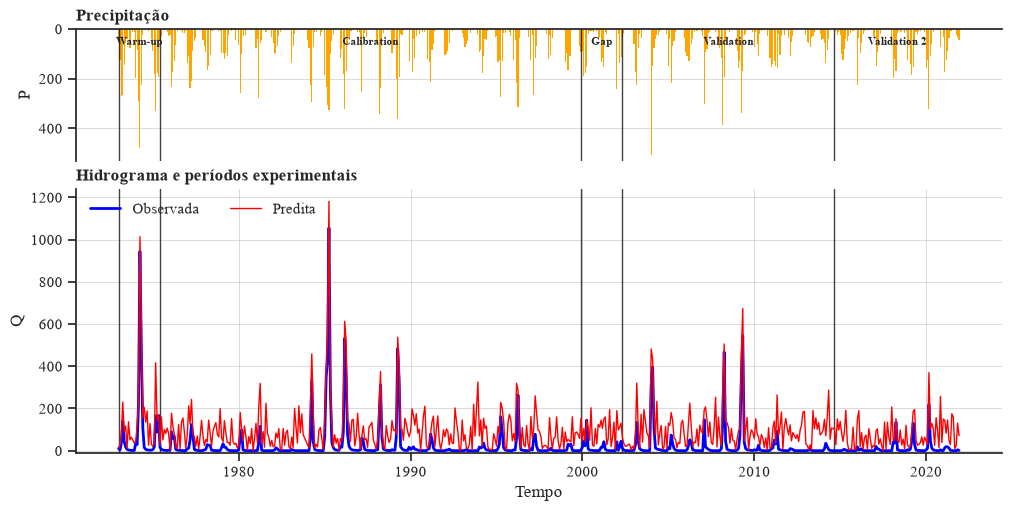

CPU times: total: 1.97 s
Wall time: 1.98 s


In [96]:
%%time
rng = np.random.default_rng(seed=7)
fig, ax_p, ax_q = evaluate_with_data_splitting(df_obs=df,
                                               Q_pred=df.loc[:, 'Q'].values + np.abs(rng.normal(size=df.shape[0], scale=100)),
                                               warmup_frac=.05,
                                               calibration_frac=.50,
                                               gap_frac=.05,
                                               validation2_frac=.15)
plt.show()